# Creating a Segmented Linear Regression Model for Cyclist Volume in Greater Adelaide

This notebook creates a set of regression predictors for cyclist volume in Greater Adelaide. The supplied cyclist count data is from the *Super Tuesday* cyclist counts, held on 3rd March 2026 from 7-9am, at 132 sites.

`graph_generation` contains the python notebooks used to retrieve the cycle network and load it with the regression data (see variable list). Check `graph_generation/graph_cache/graph_loaded.graphml` exists before this notebook is run.

X data for each count location is joined from the nearest edge of the graph, which is not exact, however the selected count locations intentionally correspond to prominent cycling routes in Adelaide, so it is assumed that the count location can snap to a nearby edge. The furthest distance from a count location to a graph edge is 20m.

## Segmentation

The model is divided into three segments - CBD, CBDP, S, SP. Regression will first be done per segment, and then combined for the final model.

__CBD__:
The main Adelaide CBD, including North Adelaide. A lot of morning cyclist traffic is destined towards here. __Edges classified by__ falling within OSM relation *R3093825* (Adelaide City Council Boundary), with Mesh Block population > 0. 15 count locations fall in this segment.

__CBDP__:
Parklands surrounding the CBD. Morning cyclist traffic from suburbs to CBD passes through here. __Edges classified by__ falling within OSM relation *R3093825* (Adelaide City Council Boundary), with Mesh Block population 0. 20 count locations fall in this segment.

__S__:
Adelaide suburbs. __Edges classified by__ falling outside OSM Relation *R3093825* with Mesh Block population > 0.

__SP__:
Suburban parklands. This includes River Torrens bikeways, locations that border on the CBD Parklands, and other parks. __Edges classified by__ falling outside OSM Relation *R3093825* with Mesh Block population 0.

Mesh Blocks are the smallest Australian Census geographical unit and conveniently align with the boundaries of the Adelaide parklands. This makes identifying the geographic region for each segment simple, as the population of an edge's corresponding Mesh Block can be found.

## Variables

See `variable_list.md` for notes on which columns were dropped for each segment.

__CBD__

- POW_CTW: N people who work in this DZN and cycle to work
- POW_FE: N people who work in this DZN and are fully engaged in employment or study
- PD_MB: MB population density
- DNL_DZN: Distance to nearest large DZN
- M_30_40, F_15_25: Age demographics, try males 30-40 and females 15-25 (best from Dadshova's)
- H_3500: Households with a THI of > 3500, place of enumeration, MB
- INF_CR: Listed cycle routes

__CBDP__

- POW_CTW: N people who work in this DZN and cycle to work
- POW_FE: N people who work in this DZN and are fully engaged in employment or study
- DNL_DZN: Distance to nearest large DZN
- INF_CR: Listed cycle routes
- MBI_BP: Dedicated bike path, Shared bike path
- MBI_PTL: Painted bike lane, Painted bike lane (single-side)
- MBI_SZ: Shared zone
- MBI_Bus: Bus lane with cycling allowed
- INF_SmRd: OSM 'highway:tertiary' or 'highway:residential' 

__S__

- POW_CTW: N people who work in this DZN and cycle to work
- POW_FE: N people who work in this DZN and are fully engaged in employment or study
- PD_MB: MB population density
- DNL_DZN: Distance to nearest large DZN
- M_30_40, F_15_25: Age demographics, males 30-40 and females 15-25
- H_3500: Households with a THI of > 3500, place of enumeration, MB
- INF_CR: Listed cycle routes
- INF_TrRd: OSM 'highway:trunk'
- INF_LgRd: OSM 'highway:primary' or 'highway:secondary'
- INF_SmRd: OSM 'highway:tertiary' or 'highway:residential'

__SP__

- POW_CTW: N people who work in this DZN and cycle to work
- POW_FE: N people who work in this DZN and are fully engaged in employment or study
- DNL_DZN: Distance to nearest large DZN
- INF_CR: Listed cycle routes
- MBI_PP: Pedestrian path/street with cycling allowed
- INF_TrRd: OSM 'highway:trunk'
- INF_LgRd: OSM 'highway:primary' or 'highway:secondary'
- MBI_BP: Dedicated bike path, Shared bike path

## Graph and Regression Setup

In [1]:
import osmnx as ox
import pandas as pd
import numpy as np
import geopandas as gpd
import networkx as nx
from scipy.spatial import cKDTree

graphml_path = "./../graph_generation/graph_cache/graph_loaded.graphml"
G = ox.load_graphml(filepath=graphml_path)
print(f"Loaded graph: {len(G.nodes)} nodes, {len(G.edges)} edges")

Loaded graph: 466150 nodes, 893094 edges


In [2]:
import pandas as pd

counts_path = "./../count_data/counts.csv"

required_cols = ["total-count", "x", "y"]

REGRESSION_TABLE = pd.read_csv(counts_path)

missing = [col for col in required_cols if col not in REGRESSION_TABLE.columns]
if missing:
    raise ValueError(f"Missing required count columns: {missing}")

REGRESSION_TABLE = REGRESSION_TABLE[required_cols].copy()
REGRESSION_TABLE = REGRESSION_TABLE.rename(columns={"total-count": "COUNT"})
REGRESSION_TABLE["COUNT"] = pd.to_numeric(REGRESSION_TABLE["COUNT"], errors="coerce")
REGRESSION_TABLE["x"] = pd.to_numeric(REGRESSION_TABLE["x"], errors="coerce")
REGRESSION_TABLE["y"] = pd.to_numeric(REGRESSION_TABLE["y"], errors="coerce")

REGRESSION_TABLE = REGRESSION_TABLE.dropna(subset=["COUNT", "x", "y"]).reset_index(drop=True)

print(REGRESSION_TABLE.head())
print(f"Rows loaded: {len(REGRESSION_TABLE)}")

   COUNT           x          y
0   49.0  138.588749 -34.899506
1   53.0  138.589951 -34.902941
2   93.0  138.599362 -34.902090
3   82.0  138.595016 -34.903023
4   44.0  138.611103 -34.903433
Rows loaded: 130


In [3]:
# Monkey patch osmnx settings so I can use geocode to gdf
import osmnx as ox
import osmnx.settings as ox_settings
if not hasattr(ox_settings, 'http_user_agent'):
    ox_settings.http_user_agent = ox_settings.default_user_agent
if not hasattr(ox_settings, 'http_referer'):
    ox_settings.http_referer = ox_settings.default_referer
if not hasattr(ox_settings, 'nominatim_url'):
    ox_settings.nominatim_url = ox_settings.nominatim_endpoint
if not hasattr(ox_settings, 'http_accept_language'):
    ox_settings.http_accept_language = ox_settings.default_accept_language


In [4]:
import geopandas as gpd

cbd_boundary = ox.geocode_to_gdf("R3093825", by_osmid=True)  # Central Adelaide LGA, incl. North Adelaide
cbd_polygon = cbd_boundary.geometry.iloc[0]

count_points_all = gpd.GeoDataFrame(
    REGRESSION_TABLE.copy(),
    geometry=gpd.points_from_xy(REGRESSION_TABLE["x"], REGRESSION_TABLE["y"]),
    crs="EPSG:4326",
)
in_cbd = count_points_all.within(cbd_polygon.buffer(0)).to_numpy()

print(f"Count rows before trim: {len(REGRESSION_TABLE)}")
print(f"Outside boundary (-> SUBURBS): {int((~in_cbd).sum())}")
# Keep ALL rows: outside-boundary rows become the SUBURBS segment, not dropped.
REGRESSION_TABLE["IN_BOUNDARY"] = in_cbd
print(f"Count rows kept (all):  {len(REGRESSION_TABLE)}")

Count rows before trim: 130
Outside boundary (-> SUBURBS): 95
Count rows kept (all):  130


In [5]:
import numpy as np

# Physical edges, deduplicated (both directions of two-way streets share tags)
nodes_gdf, edges_gdf = ox.graph_to_gdfs(G, nodes=True, edges=True)
edges_gdf = edges_gdf.reset_index()
edges_gdf["_u_v"] = [tuple(sorted((u, v))) for u, v in zip(edges_gdf["u"], edges_gdf["v"])]
edges_phys = edges_gdf.drop_duplicates(subset=["_u_v", "key"]).reset_index(drop=True)

# Snap to the nearest EDGE GEOMETRY (not midpoint) in a metric CRS, so distances are metres.
metric_crs = edges_phys.estimate_utm_crs()
edges_metric = edges_phys[["u", "v", "key", "geometry"]].to_crs(metric_crs)

count_points = gpd.GeoDataFrame(
    REGRESSION_TABLE[["COUNT", "x", "y"]].copy(),
    geometry=gpd.points_from_xy(REGRESSION_TABLE["x"], REGRESSION_TABLE["y"]),
    crs="EPSG:4326",
).to_crs(metric_crs)

snapped = gpd.sjoin_nearest(
    count_points[["geometry"]],
    edges_metric,
    how="left",
    distance_col="dist_to_edge_m",
)
# Exact ties can return more than one edge per point; keep the first.
snapped = snapped[~snapped.index.duplicated(keep="first")].sort_index()

REGRESSION_TABLE["dist_to_edge_m"] = snapped["dist_to_edge_m"].values
REGRESSION_TABLE["u"] = snapped["u"].values
REGRESSION_TABLE["v"] = snapped["v"].values
REGRESSION_TABLE["key"] = snapped["key"].values

# Look up attributes by (u, v, key), which is what the snap now returns.
edge_attrs = edges_phys.set_index(["u", "v", "key"])
attr_index = pd.MultiIndex.from_arrays([REGRESSION_TABLE["u"], REGRESSION_TABLE["v"], REGRESSION_TABLE["key"]])

edge_attr_cols = [
    "INF_CR", "MBI_BP", "MBI_PP", "MBI_PTL", "MBI_Sh", "MBI_SZ", "MBI_Bus", "MBI_Mx",
    "DNL_DZN", "PD_MB", "POW_CTW", "POW_FE", "M_30_40", "F_15_25", "H_3500",
    "INF_TrRd", "INF_LgRd", "INF_SmRd",
]
for col in edge_attr_cols:
    if col in edge_attrs.columns:
        REGRESSION_TABLE[col] = edge_attrs[col].reindex(attr_index).values
    else:
        print(f"Warning: {col} not found in edges; filled with 0")
        REGRESSION_TABLE[col] = 0

print("dist_to_edge_m (m):")
print(REGRESSION_TABLE["dist_to_edge_m"].describe().round(2).to_string())
print(f"Joined attributes. Shape: {REGRESSION_TABLE.shape}")

dist_to_edge_m (m):
count    130.00
mean       2.45
std        2.62
min        0.03
25%        0.87
50%        1.78
75%        3.35
max       20.22
Joined attributes. Shape: (130, 26)


In [6]:
# Trim count points that are too far from any edge to be on the network.
# The cutoff is set from the measured distribution (see the join cell output).
# Change MAX_SNAP_M after reviewing the distribution.
MAX_SNAP_M = 25.0  # metres; placeholder, set after inspecting dist_to_edge_m

n_before = len(REGRESSION_TABLE)
too_far = REGRESSION_TABLE["dist_to_edge_m"] > MAX_SNAP_M
print(f"Rows before trim: {n_before}")
print(f"Rows with dist_to_edge_m > {MAX_SNAP_M} m (dropped): {int(too_far.sum())}")
if too_far.any():
    print(REGRESSION_TABLE.loc[too_far, ["x", "y", "COUNT", "dist_to_edge_m"]].round(5).to_string())

REGRESSION_TABLE = REGRESSION_TABLE.loc[~too_far].reset_index(drop=True)
print(f"Rows after trim: {len(REGRESSION_TABLE)}")

Rows before trim: 130
Rows with dist_to_edge_m > 25.0 m (dropped): 0
Rows after trim: 130


In [7]:
import numpy as np
import statsmodels.api as sm

# Segment split. Inside boundary: PD_MB == 0 -> CBDP, else CBD.
# Outside boundary: PD_MB == 0 -> S, else SP.
# Coerce to numeric first (GraphML stores text).
pd_mb = pd.to_numeric(REGRESSION_TABLE["PD_MB"], errors="coerce").fillna(0)
REGRESSION_TABLE["SEGMENT"] = np.where(
    REGRESSION_TABLE["IN_BOUNDARY"],
    np.where(pd_mb == 0, "CBDP", "CBD"),
    np.where(pd_mb == 0, "SP", "S"),
)
print(REGRESSION_TABLE["SEGMENT"].value_counts())

CBD_PREDICTORS = ["POW_CTW", "POW_FE", "PD_MB", "DNL_DZN", "M_30_40",
            "F_15_25", "INF_CR", "MBI_PTL", "INF_LgRd", "INF_SmRd"]
CBDP_PREDICTORS = ["POW_CTW", "POW_FE", "DNL_DZN", "INF_CR", "MBI_BP",
            "MBI_PTL", "MBI_SZ", "MBI_Bus", "INF_SmRd"]
S_PREDICTORS = ["POW_CTW", "POW_FE", "PD_MB", "DNL_DZN", "M_30_40",
            "F_15_25", "H_3500", "INF_CR", "INF_TrRd",
            "INF_LgRd", "INF_SmRd"]
SP_PREDICTORS = ["POW_CTW", "POW_FE", "DNL_DZN", "INF_CR", "MBI_PP",
            "INF_TrRd", "INF_LgRd", "MBI_BP"]

def build_design(segment_name, predictors):
    seg = REGRESSION_TABLE.loc[REGRESSION_TABLE["SEGMENT"] == segment_name]
    cols = [c for c in predictors if c in seg.columns]
    data = seg[["COUNT"] + cols].dropna()
    # drop zero-variance predictors
    cols = [c for c in cols if data[c].nunique() > 1]
    data = data[["COUNT"] + cols]
    y = data["COUNT"]
    X = sm.add_constant(data[cols], has_constant="add")
    return X, y, cols

X_CBD, y_CBD, CBD_COLS = build_design("CBD", CBD_PREDICTORS)
X_S, y_S, S_COLS = build_design("S", S_PREDICTORS)  # full set, per user choice
X_SP, y_SP, SP_COLS = build_design("SP", SP_PREDICTORS)
X_CBDP, y_CBDP, CBDP_COLS = build_design("CBDP", CBDP_PREDICTORS)

print(f"X_CBD: {X_CBD.shape}, y mean {y_CBD.mean():.2f}, var {y_CBD.var():.2f}")
print(f"X_CBDP: {X_CBDP.shape}, y mean {y_CBDP.mean():.2f}, var {y_CBDP.var():.2f}")
print(f"X_S: {X_S.shape}, y mean {y_S.mean():.2f}, var {y_S.var():.2f}")
print(f"X_SP: {X_SP.shape}, y mean {y_SP.mean():.2f}, var {y_SP.var():.2f}")

SEGMENT
S       74
SP      21
CBDP    19
CBD     16
Name: count, dtype: int64
X_CBD: (16, 11), y mean 222.69, var 14347.30
X_CBDP: (19, 9), y mean 160.84, var 7470.47
X_S: (74, 12), y mean 66.59, var 4110.16
X_SP: (21, 9), y mean 90.00, var 10069.70


In [8]:
# Save the predictor correlation matrix (plus COUNT) for each segment as CSV.
# Use these to spot collinear predictors before reading the fits.
import os
import pandas as pd

output_dir = "./model_data/segment_correlations"
os.makedirs(output_dir, exist_ok=True)

segment_designs = {
    "CBD": (X_CBD, y_CBD),
    "CBDP": (X_CBDP, y_CBDP),
    "S": (X_S, y_S),
    "SP": (X_SP, y_SP),
}

for name, (X_seg, y_seg) in segment_designs.items():
    # Drop the constant column; it has no correlation and would be NaN.
    data = X_seg.drop(columns="const", errors="ignore").copy()
    data["COUNT"] = y_seg.values
    out_path = os.path.join(output_dir, f"correlation_{name}.csv")
    if data.shape[1] < 2:
        print(f"{name}: not enough columns for a correlation matrix; skipped")
        continue
    corr = data.corr().round(3)
    corr.to_csv(out_path)
    print(f"{name} (n={len(data)}): saved {out_path} {corr.shape}")

CBD (n=16): saved ./model_data/segment_correlations/correlation_CBD.csv (11, 11)
CBDP (n=19): saved ./model_data/segment_correlations/correlation_CBDP.csv (9, 9)
S (n=74): saved ./model_data/segment_correlations/correlation_S.csv (12, 12)
SP (n=21): saved ./model_data/segment_correlations/correlation_SP.csv (9, 9)


__*Export Separate Matrices*__

In [9]:
output_dir = "./model_data/X_y_segments"
os.makedirs(output_dir, exist_ok=True)
export_cbd = X_CBD.copy()
export_cbd["COUNT"] = y_CBD.values
export_cbd.to_csv("./model_data/X_y_segments/CBD.csv", index=False)

export_cbdp = X_CBDP.copy()
export_cbdp["COUNT"] = y_CBDP.values
export_cbdp.to_csv("./model_data/X_y_segments/CBDP.csv", index=False)

export_s = X_S.copy()
export_s["COUNT"] = y_S.values
export_s.to_csv("./model_data/X_y_segments/S.csv", index=False)

export_sp = X_SP.copy()
export_sp["COUNT"] = y_SP.values
export_sp.to_csv("./model_data/X_y_segments/SP.csv", index=False)

print(f"Exported CBD: {export_cbd.shape}; CBDP: {export_cbdp.shape}; S: {export_s.shape}; SP: {export_sp.shape}")

Exported CBD: (16, 12); CBDP: (19, 10); S: (74, 13); SP: (21, 10)


## Fit Linear Models per Segment

In [10]:
def save_summary(model, label, out_dir="./model_data/segment_summaries/"):
    os.makedirs(out_dir, exist_ok=True)
    with open(os.path.join(out_dir, f"summary_{label}.txt"), "w") as f:
        f.write(model.summary().as_text())

    with open(os.path.join(out_dir, f"summary_{label}_latex.tex"), "w") as f:
        f.write(model.summary().as_latex())


def fit_ols(y, X, label):
    model = sm.OLS(y, X).fit(maxiter=500, disp=False)
    save_summary(model, label)
    return model

ols_CBD = fit_ols(y_CBD, X_CBD, "CBD")
ols_CBDP = fit_ols(y_CBDP, X_CBDP, "CBDP")
ols_S = fit_ols(y_S, X_S, "S")
ols_SP = fit_ols(y_SP, X_SP, "SP")

## Combine segments for final model

In [11]:
import os
# Combined segmented OLS: one design matrix, separate slopes and intercept per segment.
# Each (segment, predictor) pair gets its own column: x * I(SEGMENT == segment).
# Segment intercept dummies replace a global constant, so segments are not forced to share one.
import numpy as np
import statsmodels.api as sm

SEGMENT_PREDICTORS = {
    "CBD": CBD_PREDICTORS,
    "CBDP": CBDP_PREDICTORS,
    "S": S_PREDICTORS,
    "SP": SP_PREDICTORS,
}
SEGMENTS = list(SEGMENT_PREDICTORS)

# 1. Drop rows missing any predictor used by their own segment, so all segments are aligned.
all_cols = sorted({c for cols in SEGMENT_PREDICTORS.values() for c in cols} | {"COUNT", "SEGMENT"})
combined_base = REGRESSION_TABLE[all_cols].copy()
combined_base["PD_MB"] = pd.to_numeric(combined_base["PD_MB"], errors="coerce")
for col in all_cols:
    if col not in ("SEGMENT",):
        combined_base[col] = pd.to_numeric(combined_base[col], errors="coerce")

seg_mask = combined_base["SEGMENT"].isin(SEGMENTS)
needed = {s: SEGMENT_PREDICTORS[s] for s in SEGMENTS}
ok = pd.Series(True, index=combined_base.index)
for s, cols in needed.items():
    in_s = combined_base["SEGMENT"] == s
    ok &= ~in_s | combined_base[cols].notna().all(axis=1)
combined_base = combined_base.loc[seg_mask & ok].copy()

print("Rows per segment after NaN drop:")
print(combined_base["SEGMENT"].value_counts().to_string())

# 2. Build interaction columns and segment intercept dummies.
blocks = {}
kept_terms = {}
for s in SEGMENTS:
    in_s = (combined_base["SEGMENT"] == s).astype(float)
    blocks[f"I_{s}"] = in_s
    for col in SEGMENT_PREDICTORS[s]:
        name = f"{col}_{s}"
        blocks[name] = combined_base[col].astype(float) * in_s

combined_X = pd.DataFrame(blocks, index=combined_base.index)
combined_y = combined_base["COUNT"].astype(float)

# 3. Zero-variance filter on the combined matrix. Keep segment intercepts unconditionally.
keep = [c for c in combined_X.columns if c.startswith("I_") or combined_X[c].nunique() > 1]
combined_X = combined_X[keep]

# 4. Full-rank check: a singular combined matrix means the fit is not identified.
rank = np.linalg.matrix_rank(combined_X.values)
print(f"Combined design: {combined_X.shape}, rank {rank}, residual df {combined_X.shape[0] - rank}")
if rank < combined_X.shape[1]:
    print("WARNING: combined matrix is rank-deficient; coefficients are not uniquely identified.")

# 5. Fit once, OLS, with no extra constant (segment intercepts already present).
combined_model = sm.OLS(combined_y, combined_X).fit()
save_summary(combined_model, "combined")

# 6. Compare pooled slopes with the separate per-segment fits.
print("\nCombined vs separate-segment coefficients:")
for s, sep in [("CBD", ols_CBD), ("CBDP", ols_CBDP), ("S", ols_S), ("SP", ols_SP)]:
    for col in sep.params.index:
        if col == "const":
            continue
        cname = f"{col}_{s}"
        if cname in combined_model.params.index:
            print(f"{s:5s} {col:10s} separate={sep.params[col]:12.3f}  combined={combined_model.params[cname]:12.3f}")

# 7. Export the combined matrix with the segment label kept, so it can be re-split later.
combined_export = combined_X.copy()
combined_export["COUNT"] = combined_y.values
combined_export["SEGMENT"] = combined_base["SEGMENT"].values
combined_export.to_csv("./model_data/X_y_segments/combined.csv", index=False)
print(f"\nExported combined matrix: {combined_export.shape}")

# Export coefficients so the edge prediction step can reload them from CSV.
os.makedirs("./model_data", exist_ok=True)
coef_table = pd.DataFrame({
    "term": combined_model.params.index,
    "coef": combined_model.params.values,
    "std_err": combined_model.bse.values,
    "p_value": combined_model.pvalues.values,
})
coef_table.to_csv("./model_data/combined_coefficients.csv", index=False)
print(f"Saved combined_coefficients.csv ({len(coef_table)} terms)")


Rows per segment after NaN drop:
SEGMENT
S       74
SP      21
CBDP    19
CBD     16
Combined design: (130, 41), rank 41, residual df 89

Combined vs separate-segment coefficients:
CBD   POW_CTW    separate=       1.798  combined=       1.798
CBD   POW_FE     separate=      -0.078  combined=      -0.078
CBD   PD_MB      separate=       0.011  combined=       0.011
CBD   DNL_DZN    separate=      -0.129  combined=      -0.129
CBD   M_30_40    separate=     -19.407  combined=     -19.407
CBD   F_15_25    separate=     -12.303  combined=     -12.303
CBD   INF_CR     separate=      10.719  combined=      10.719
CBD   MBI_PTL    separate=      25.311  combined=      25.311
CBD   INF_LgRd   separate=      20.531  combined=      20.531
CBD   INF_SmRd   separate=     -94.989  combined=     -94.989
CBDP  POW_CTW    separate=       1.391  combined=       1.391
CBDP  POW_FE     separate=      -0.058  combined=      -0.058
CBDP  DNL_DZN    separate=      -0.049  combined=      -0.049
CBDP  INF_CR 

In [12]:
# Predict PREDICTED_COUNT for every graph edge using the reloaded combined coefficients.
# Simple loop: classify each edge into a segment, then apply coefficients. Clip negatives to 0.
import pandas as pd
import osmnx as ox
import networkx as nx
from shapely.geometry import Point

coef_table = pd.read_csv("./model_data/combined_coefficients.csv")
coef = dict(zip(coef_table["term"], coef_table["coef"].astype(float)))

boundary_poly = ox.geocode_to_gdf("R3093825", by_osmid=True).to_crs("EPSG:4326").geometry.iloc[0]

def num(data, name):
    # GraphML stores everything as text; cast explicitly.
    try:
        return float(data.get(name, 0) or 0)
    except (TypeError, ValueError):
        return 0.0

predicted = {}
segments = {}
for u, v, key, data in G.edges(keys=True, data=True):
    x_mid = (G.nodes[u]["x"] + G.nodes[v]["x"]) / 2
    y_mid = (G.nodes[u]["y"] + G.nodes[v]["y"]) / 2
    in_boundary = boundary_poly.contains(Point(x_mid, y_mid))

    pd_mb = num(data, "PD_MB")
    if in_boundary:
        seg = "CBDP" if pd_mb == 0 else "CBD"
    else:
        seg = "SP" if pd_mb == 0 else "S"

    value = coef.get(f"I_{seg}", 0.0)
    for term, c in coef.items():
        if term == "const" or term.startswith("I_"):
            continue
        base, _, term_seg = term.rpartition("_")
        if term_seg == seg:
            value += c * num(data, base)

    predicted[(u, v, key)] = max(value, 0.0)
    segments[(u, v, key)] = seg

nx.set_edge_attributes(G, predicted, "PREDICTED_COUNT")
nx.set_edge_attributes(G, segments, "SEGMENT")

vals = pd.Series(list(predicted.values()))
print(f"Edges predicted: {len(predicted)}")
print(f"PREDICTED_COUNT: min={vals.min():.2f} max={vals.max():.2f} mean={vals.mean():.2f}")
print(pd.Series(list(segments.values())).value_counts().to_string())


Edges predicted: 893094
PREDICTED_COUNT: min=0.00 max=721.10 mean=45.75
S       677204
SP      188971
CBDP     13955
CBD      12964


In [13]:
# Light export: copy only PREDICTED_COUNT onto a new graph built from the edges
# (the full ~1GB GraphML is not re-written here), then save GraphML and GeoPackage.
import os
import pandas as pd
import geopandas as gpd
import networkx as nx
import osmnx as ox
import matplotlib.pyplot as plt

os.makedirs("./model_data/prediction", exist_ok=True)

# Edge table from the fully loaded graph, carrying only the prediction.
_nodes, _edges = ox.graph_to_gdfs(G, nodes=True, edges=True)
_edges = _edges.reset_index()[["u", "v", "key", "PREDICTED_COUNT", "geometry"]].copy()
_edges["PREDICTED_COUNT"] = pd.to_numeric(_edges["PREDICTED_COUNT"], errors="coerce").astype(int)

# Light graph: nodes + edges with PREDICTED_COUNT only.
G_light = nx.MultiDiGraph(crs=G.graph.get("crs", "EPSG:4326"))
for nid, nd in _nodes.iterrows():
    G_light.add_node(nid, x=float(nd["x"]), y=float(nd["y"]))
for row in _edges.itertuples(index=False):
    G_light.add_edge(row.u, row.v, key=row.key,
                     PREDICTED_COUNT=float(row.PREDICTED_COUNT), geometry=row.geometry)

light_path = "./model_data/prediction/predicted_graph.graphml"
ox.save_graphml(G_light, filepath=light_path)
print(f"Saved light graphml: {light_path}")

gpkg_path = "./model_data/prediction/predicted_edges.gpkg"
_edges.to_file(gpkg_path, driver="GPKG", layer="edges_pred")
print(f"Saved GeoPackage: {gpkg_path}")

Saved light graphml: ./model_data/prediction/predicted_graph.graphml
Saved GeoPackage: ./model_data/prediction/predicted_edges.gpkg


Saved PNG: ./model_data/prediction/predicted_edges.png


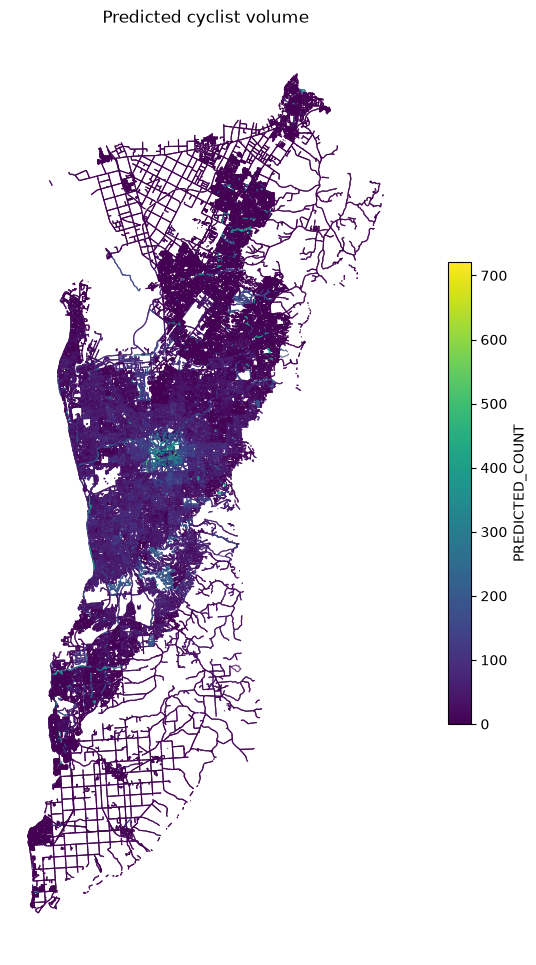

In [14]:
# PNG for quick viewing, coloured by PREDICTED_COUNT.
fig, ax = plt.subplots(figsize=(12, 12))
_edges.plot(column="PREDICTED_COUNT", ax=ax, linewidth=0.8, cmap="viridis", legend=True,
            legend_kwds={"label": "PREDICTED_COUNT", "shrink": 0.5})
ax.set_title("Predicted cyclist volume")
ax.set_axis_off()
png_path = "./model_data/prediction/predicted_edges.png"
fig.savefig(png_path, dpi=200, bbox_inches="tight")
print(f"Saved PNG: {png_path}")
